# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

## Carregando o Dataset

In [4]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

car_evaluation = fetch_ucirepo(id=19)
df = pd.concat([car_evaluation.data.features, car_evaluation.data.targets], axis=1)
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Car Evaluation tem 6 variáveis preditoras (preço de compra, custo de manutenção, número de portas, capacidade de passageiros, tamanho do porta-malas e nível de segurança) mais o alvo (`class`, aceitabilidade do carro). Como o dataset foi gerado combinando **todas** as categorias possíveis de cada atributo, quantas linhas vocês esperam encontrar — dezenas, centenas ou milhares?

### Dimensão e Tipos de Dados

In [5]:
df.shape

(1728, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [7]:
df.describe(include="all")

,buying,maint,doors,persons,lug_boot,safety,class
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,2,2,small,low,unacc
freq,432,432,432,576,576,576,1210


### Duplicadas

In [8]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `class` com 4 categorias: `unacc` (inaceitável), `acc` (aceitável), `good` (bom) e `vgood` (muito bom). Pra hoje, vamos simplificar para uma variável binária, **aceitável** ou **não aceitável**, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = não aceitável, roxo = aceitável).

Guardamos também a versão original de 4 classes em `avaliacao_4`, porque ela vai ser útil mais à frente nos testes que comparam 3+ grupos (ANOVA / Kruskal-Wallis).

In [9]:
if "class" in df.columns:
    df["avaliacao_4"] = pd.Categorical(df["class"],
                                       categories=["unacc", "acc", "good", "vgood"],
                                       ordered=True)
    df["avaliacao"] = np.where(df["class"] == "unacc", "Não Aceitável", "Aceitável")
    df.drop(columns=["class"], inplace=True)

print("Alvo original (4 classes):")
print(df["avaliacao_4"].value_counts().sort_index())
print("\nAlvo binarizado:")
print(df["avaliacao"].value_counts())
df.head()

Alvo original (4 classes):
avaliacao_4
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Alvo binarizado:
avaliacao
Não Aceitável    1210
Aceitável         518
Name: count, dtype: int64


,buying,maint,doors,persons,lug_boot,safety,avaliacao_4,avaliacao
0,vhigh,vhigh,2,2,small,low,unacc,Não Aceitável
1,vhigh,vhigh,2,2,small,med,unacc,Não Aceitável
2,vhigh,vhigh,2,2,small,high,unacc,Não Aceitável
3,vhigh,vhigh,2,2,med,low,unacc,Não Aceitável
4,vhigh,vhigh,2,2,med,med,unacc,Não Aceitável


### Codificação ordinal das variáveis

Todas as 6 features do Car Evaluation são categóricas, mas nenhuma delas é *nominal*: todas têm uma **ordem natural** (`low` < `med` < `high` < `vhigh`, `small` < `med` < `big`, e assim por diante). Isso é importante porque várias técnicas da aula (ECDF, mediana, IQR, correlação de Spearman, Mann-Whitney) exigem valores que possam ser **ordenados**, não apenas contados.

A solução é registrar essa ordem explicitamente e criar uma versão codificada de cada variável (`buying_cod`, `safety_cod`, ...), guardando o original para os gráficos de frequência. Definimos tudo em um único lugar para não repetir a ordem em cada célula.

In [10]:
ORDEM_CATEGORIAS = {
    "buying":   ["low", "med", "high", "vhigh"],
    "maint":    ["low", "med", "high", "vhigh"],
    "doors":    ["2", "3", "4", "5more"],
    "persons":  ["2", "4", "more"],
    "lug_boot": ["small", "med", "big"],
    "safety":   ["low", "med", "high"],
}

VARS_QUALI = list(ORDEM_CATEGORIAS) + ["avaliacao"]

for col, ordem in ORDEM_CATEGORIAS.items():
    df[col] = pd.Categorical(df[col].astype(str), categories=ordem, ordered=True)
    df[f"{col}_cod"] = df[col].cat.codes

VARS_ORDINAIS_COD = [f"{col}_cod" for col in ORDEM_CATEGORIAS]

print("Qualitativas:", VARS_QUALI)
print("Ordinais codificadas:", VARS_ORDINAIS_COD)
df[list(ORDEM_CATEGORIAS) + VARS_ORDINAIS_COD].head()

Qualitativas: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'avaliacao']
Ordinais codificadas: ['buying_cod', 'maint_cod', 'doors_cod', 'persons_cod', 'lug_boot_cod', 'safety_cod']


,buying,maint,doors,persons,lug_boot,safety,buying_cod,maint_cod,doors_cod,persons_cod,lug_boot_cod,safety_cod
0,vhigh,vhigh,2,2,small,low,3,3,0,0,0,0
1,vhigh,vhigh,2,2,small,med,3,3,0,0,0,1
2,vhigh,vhigh,2,2,small,high,3,3,0,0,0,2
3,vhigh,vhigh,2,2,med,low,3,3,0,0,1,0
4,vhigh,vhigh,2,2,med,med,3,3,0,0,1,1


## 2. Dados Faltantes

In [11]:
df.isna().sum()

buying          0
maint           0
doors           0
persons         0
lug_boot        0
safety          0
avaliacao_4     0
avaliacao       0
buying_cod      0
maint_cod       0
doors_cod       0
persons_cod     0
lug_boot_cod    0
safety_cod      0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Não, está tudo perfeito.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual **não há valores ausentes** em nenhuma feature.

Pela fonte de dados observamos que:

- O dataset foi derivado de um modelo hierárquico de decisão simples, criado para avaliar carros com base em critérios bem definidos (preço, manutenção, portas, capacidade, porta-malas e segurança).
- Diferente de dados médicos ou pesquisas com humanos, aqui os valores foram gerados a partir de **todas as combinações possíveis** das categorias de cada atributo, não coletados de fontes externas sujeitas a falhas de registro.

*Como os dados foram coletados:*

- O conjunto de dados foi construído a partir de um sistema especialista (DEX) que avalia carros combinando sistematicamente os valores de cada atributo, resultando em todas as 1728 combinações possíveis.

*Qual a natureza da fonte de dados:*

- Por ser um dataset gerado de forma combinatória e completa, não existe o risco de ausência de dados que normalmente ocorre em coletas com pessoas ou sensores (como exames não realizados ou falhas de equipamento).

**As ausencias ocorrem juntas?**

Não se aplica neste caso — como não há dados faltantes, não existe padrão de ausência a ser investigado. Essa etapa da análise (MCAR, MAR, MNAR) normalmente relevante em datasets com missing values, aqui serve como ponto de comparação: nem todo dataset apresenta esse desafio, e é importante saber identificar isso logo no início da EDA.



In [12]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
                                        rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
else:
    print("Não há colunas com valores ausentes neste dataset — etapa não aplicável ao Car Evaluation.")

Não há colunas com valores ausentes neste dataset — etapa não aplicável ao Car Evaluation.


**Pra discutir:** como a contagem de ausentes por coluna já voltou zerada, não há nenhuma linha com duas ausências simultâneas — logo, não há padrão de ausência a classificar aqui. Vale mesmo assim registrar o raciocínio: **se** houvesse ausentes neste dataset, qual mecanismo seria o mais plausível, dado que os dados são gerados por um sistema especialista e não coletados de pessoas?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

*Resposta*: em um dataset gerado por combinação exaustiva, a ausência só poderia vir de uma falha na geração ou na exportação do arquivo — nunca do próprio valor. Ou seja, o mecanismo esperado seria **MCAR**: a falha não teria relação nem com o valor faltante (o que caracterizaria MNAR) nem com outra variável observada (MAR).

Esse é justamente o contraste com dados coletados de pessoas. No Heart Disease da demonstração, a ausência em `ca` / `thal` é ambígua: pode ser MNAR (o exame não foi pedido porque já se suspeitava do resultado) ou MAR/MCAR (o protocolo ou o custo limitou a coleta, independente do resultado provável). Ali não dá pra decidir só olhando os dados — precisaria de testes estatísticos e de conversar com quem coletou. Aqui, a própria natureza da fonte já responde a pergunta.

**Nota:** este dataset não exercita a parte de tratamento de ausentes, e isso em si é um resultado da EDA — vale registrar em vez de esconder. Em um dataset com *muitas* colunas e *muitos* ausentes, aí sim um heatmap de correlação entre os indicadores de ausência passaria a fazer sentido, e a decisão entre imputar e remover precisaria ser justificada.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou categorias raras), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção.

Uma observação importante de método: como **todas** as variáveis aqui são categóricas, as estatísticas usuais mudam. Não faz sentido calcular média, assimetria (*skewness*) ou curtose de `buying` ou `safety` — o que descreve a distribuição de uma variável categórica é a **tabela de frequências**. Onde a ordem das categorias permite (e aqui permite, porque todas são ordinais), recuperamos também mediana, IQR e correlação usando a versão codificada.

In [13]:
desc_quali = pd.DataFrame({
    col: df[col].value_counts(normalize=True).sort_index() * 100
    for col in VARS_QUALI
}).T

desc_quali.columns.name = "Categoria (%)"
desc_quali.style.background_gradient(cmap="magma", axis=1).format(precision=1, na_rep="—")

Categoria (%),2,3,4,5more,Aceitável,Não Aceitável,big,high,low,med,more,small,vhigh
buying,—,—,—,—,—,—,—,25.0,25.0,25.0,—,—,25.0
maint,—,—,—,—,—,—,—,25.0,25.0,25.0,—,—,25.0
doors,25.0,25.0,25.0,25.0,—,—,—,—,—,—,—,—,—
persons,33.3,—,33.3,—,—,—,—,—,—,—,33.3,—,—
lug_boot,—,—,—,—,—,—,33.3,—,—,33.3,—,33.3,—
safety,—,—,—,—,—,—,—,33.3,33.3,33.3,—,—,—
avaliacao,—,—,—,—,30.0,70.0,—,—,—,—,—,—,—


**Pra discutir:** olhando a tabela, alguma categoria aparece com frequência muito baixa ou muito alta dentro da sua variável?

Repare no contraste entre as **features** e o **alvo**: nas 6 features as frequências são praticamente idênticas entre categorias, porque o dataset foi construído combinando todas as possibilidades (cada categoria aparece o mesmo número de vezes por construção). Já `avaliacao` é bem desbalanceada. Isso é coerente com o domínio — a maioria das combinações possíveis de carro resulta em um carro inaceitável.

### Distribuições de dados

Onde fizer sentido, comparamos "Não Aceitável" (rosa) vs. "Aceitável" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


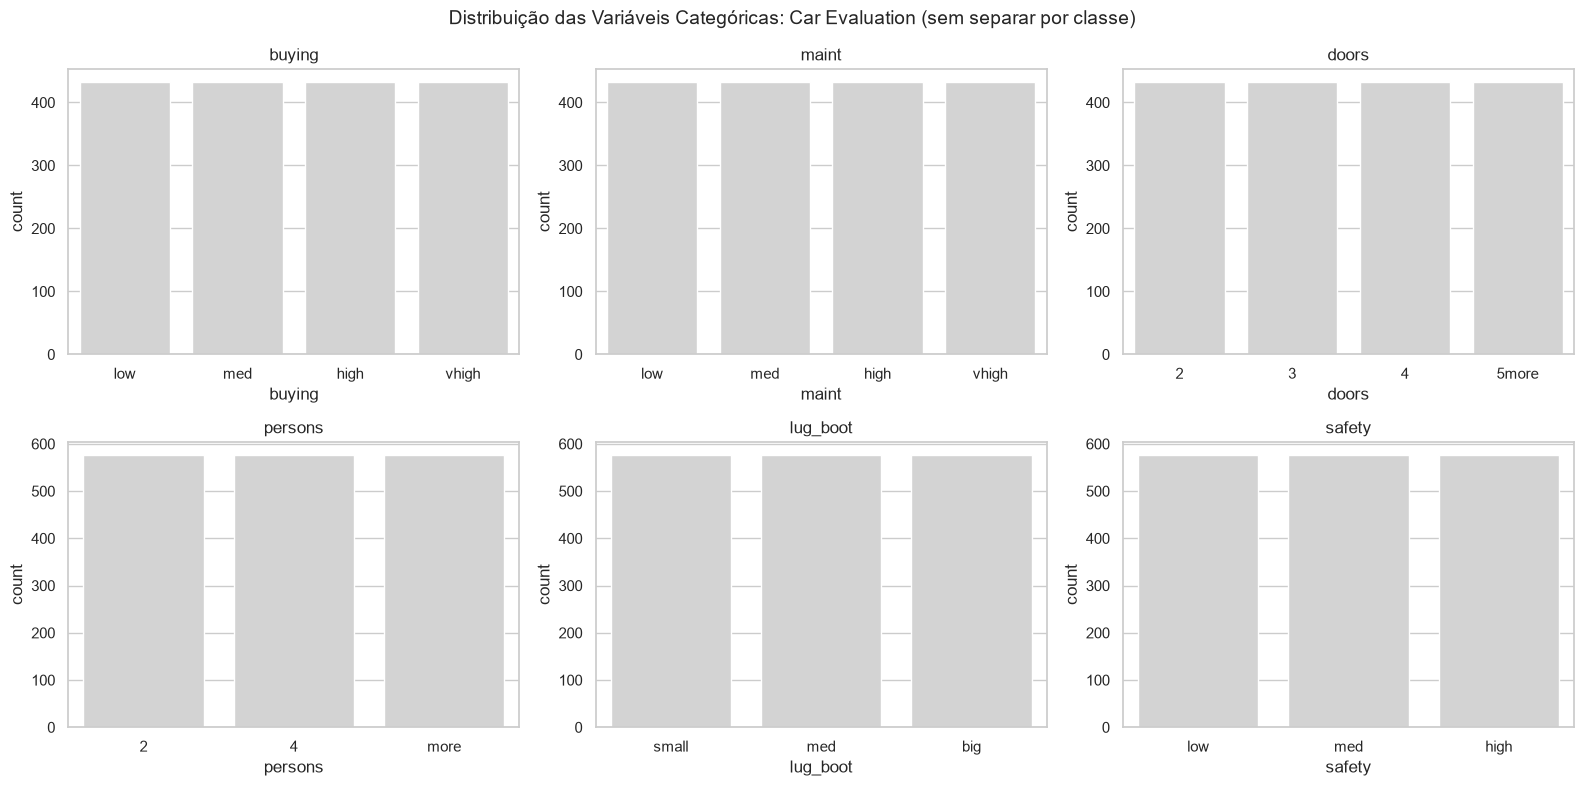

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(ORDEM_CATEGORIAS):
    sns.countplot(data=df, x=col, order=ORDEM_CATEGORIAS[col], color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(ORDEM_CATEGORIAS):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Categóricas: Car Evaluation (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

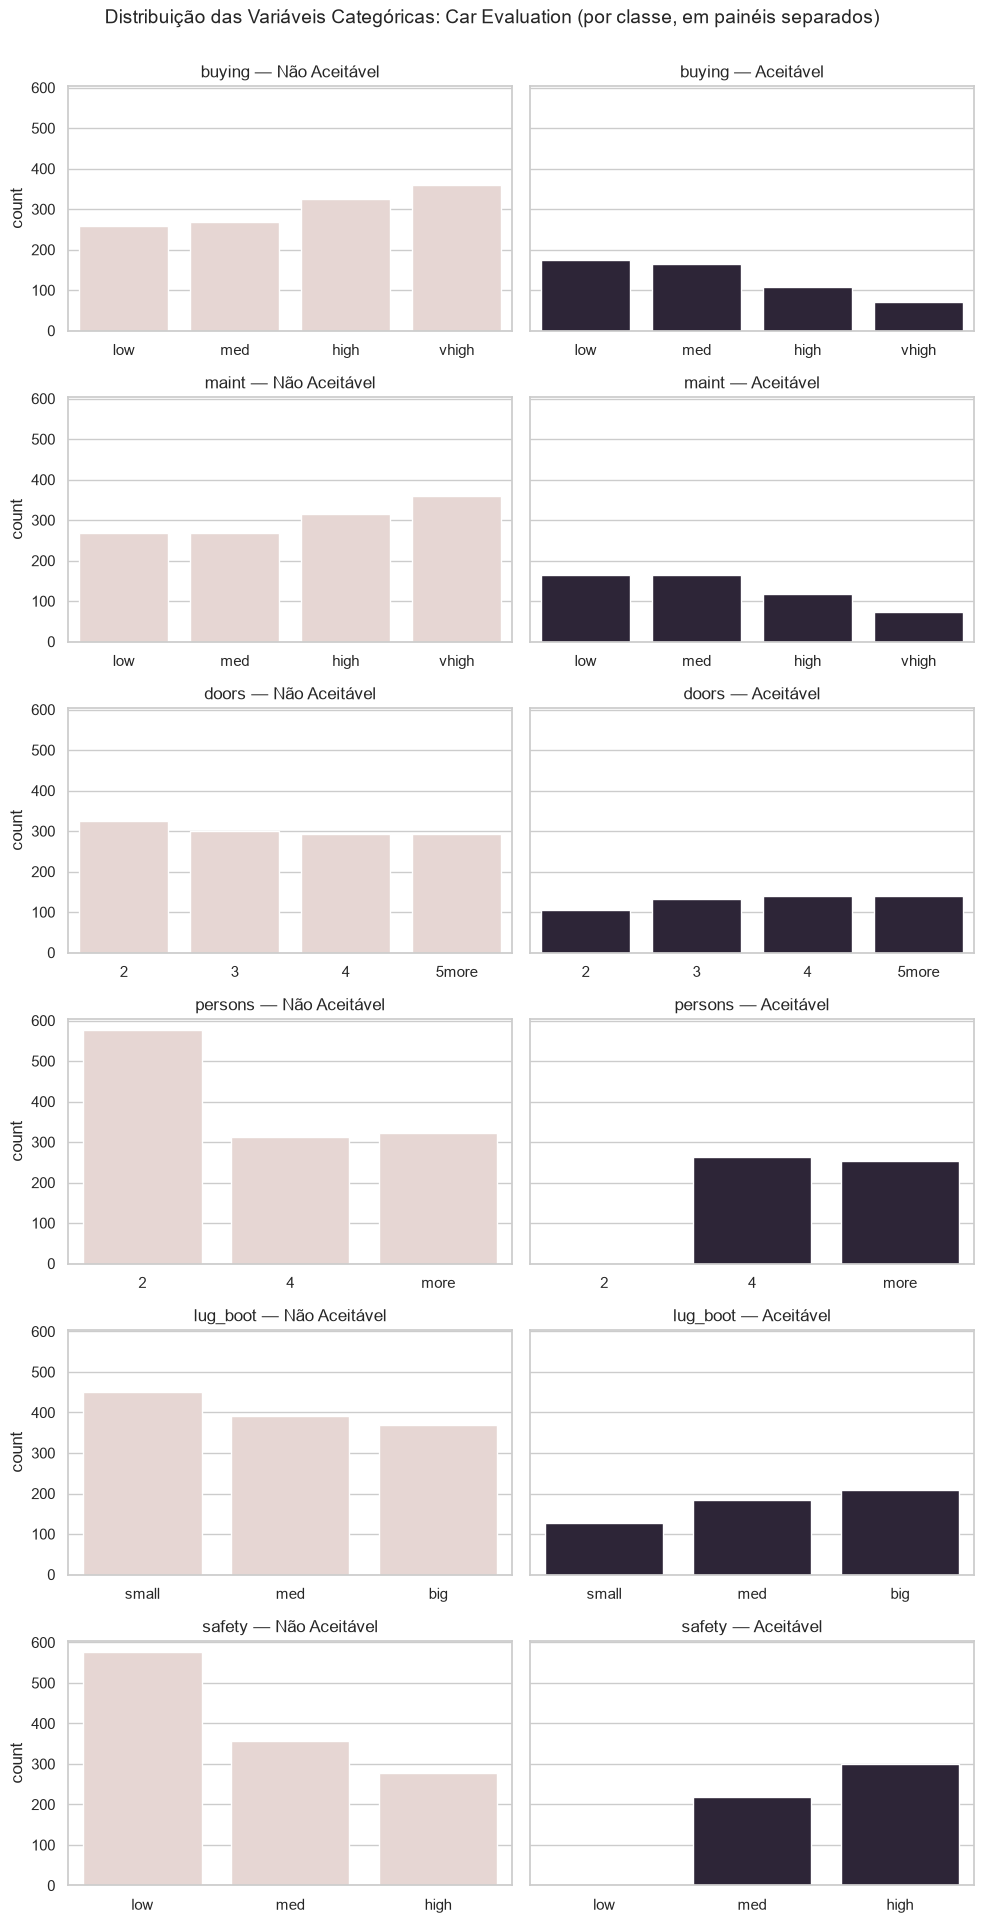

In [15]:
fig, axes = plt.subplots(len(ORDEM_CATEGORIAS), 2,
                         figsize=(10, 3.2 * len(ORDEM_CATEGORIAS)), sharey=True)

for i, col in enumerate(ORDEM_CATEGORIAS):
    for j, (classe, cor) in enumerate([("Não Aceitável", COR_CONTEXTO), ("Aceitável", COR_DESTAQUE)]):
        subset = df[df["avaliacao"] == classe]
        sns.countplot(data=subset, x=col, order=ORDEM_CATEGORIAS[col], color=cor, ax=axes[i, j])
        axes[i, j].set_title(f"{col} — {classe}")
        axes[i, j].set_xlabel("")

fig.suptitle("Distribuição das Variáveis Categóricas: Car Evaluation (por classe, em painéis separados)",
             fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo Y em cada linha), fica mais fácil ver: alguma variável tem formato bem diferente entre "Não Aceitável" e "Aceitável"? Repare especialmente em `safety` e `persons` — se alguma categoria praticamente desaparece do painel "Aceitável", isso é um indício forte de que aquela variável é decisiva para o alvo.

### Testes de Aderência

*Será se as categorias de `buying` são uniformemente distribuídas?*

O **teste Qui-Quadrado de aderência** verifica se a frequência observada de cada categoria é compatível com uma distribuição esperada (aqui, uniforme). Vamos testar com `buying`.

Qui-Quadrado — buying: estatística=0.0000, p-valor=1
Rejeita H0 (distribuição uniforme)? Não (alpha = 0.05)


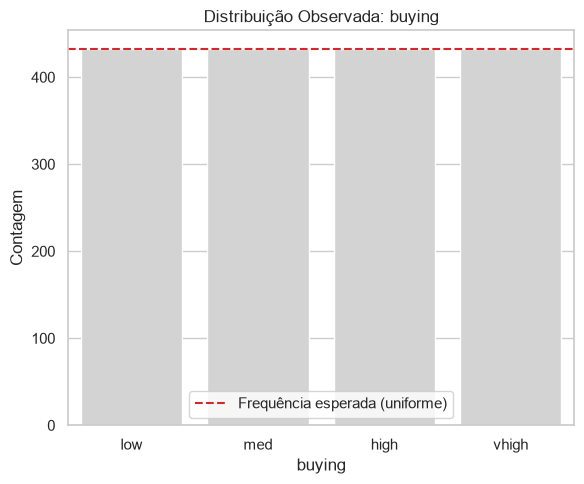

In [16]:
from scipy.stats import chisquare

freq_obs = df["buying"].value_counts().sort_index()
stat_chi2, p_valor_chi2 = chisquare(freq_obs)

print(f"Qui-Quadrado — buying: estatística={stat_chi2:.4f}, p-valor={p_valor_chi2:.4g}")
print("Rejeita H0 (distribuição uniforme)?", "Sim" if p_valor_chi2 < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=freq_obs.index, y=freq_obs.values, color=COR_NEUTRA, ax=ax)
ax.axhline(freq_obs.mean(), color=COR_ALERTA, linestyle="--", label="Frequência esperada (uniforme)")
ax.set_title("Distribuição Observada: buying")
ax.set_ylabel("Contagem")
ax.legend()
plt.tight_layout()
plt.show()

**Como ler:** se as barras (cinza) estivessem próximas da linha tracejada (vermelha), a variável seguiria uma distribuição uniforme entre as categorias. Barras muito acima ou abaixo da linha indicam desbalanceamento — coerente com o resultado do Qui-Quadrado acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a uniformidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são uniformes. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n=1728 (amostra grande), é esperado que o teste seja bastante sensível a qualquer desbalanceamento — por isso vale olhar também o tamanho do efeito (a diferença real entre as frequências), não só o p-valor.

- **Como afirmar o resultado:** quando o teste **rejeita H0** (p < 0.05), a afirmação correta é "temos evidência estatística **contra** a distribuição uniforme", que é uma conclusão forte. A frase "não podemos garantir uniformidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são uniformes, só que não há evidência suficiente contra.

In [17]:
resultados_chi2 = []
for col in VARS_QUALI[:-1]:
    freq_obs = df[col].value_counts().sort_index()
    stat, p = chisquare(freq_obs)
    resultados_chi2.append({"variavel": col, "estatistica": round(stat, 4),
                             "p_valor": round(p, 6), "rejeita_uniformidade": p < 0.05})

pd.DataFrame(resultados_chi2).set_index("variavel")

,estatistica,p_valor,rejeita_uniformidade
variavel,,,
buying,0.0,1.0,False
maint,0.0,1.0,False
doors,0.0,1.0,False
persons,0.0,1.0,False
lug_boot,0.0,1.0,False
safety,0.0,1.0,False


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de *bins*: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Como a ECDF exige valores ordenáveis, usamos aqui a versão codificada de `safety` (`safety_cod`), que criamos na seção de codificação ordinal. A leitura continua sendo em categorias — apenas rotulamos o eixo de volta com `low`, `med` e `high`.

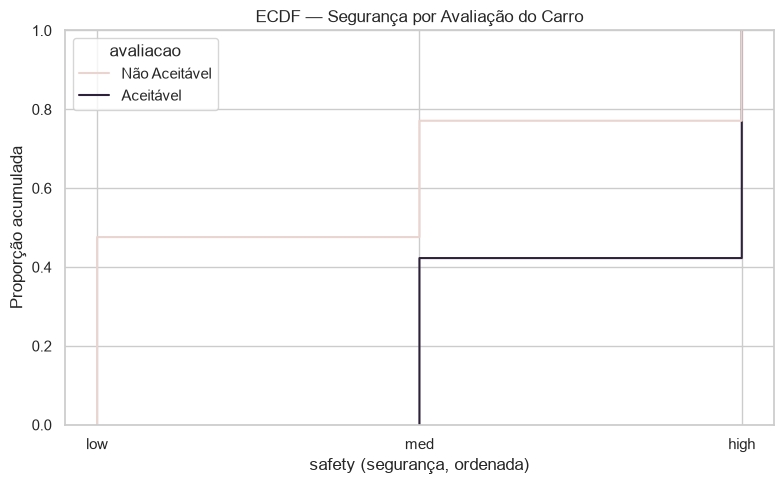

In [18]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="safety_cod", hue="avaliacao",
             palette={"Não Aceitável": COR_CONTEXTO, "Aceitável": COR_DESTAQUE})
plt.xticks(range(len(ORDEM_CATEGORIAS["safety"])), ORDEM_CATEGORIAS["safety"])
plt.title("ECDF — Segurança por Avaliação do Carro")
plt.xlabel("safety (segurança, ordenada)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos carros desse grupo tem segurança até este nível". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está o nível de segurança onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

Para variáveis categóricas, a média não existe. A medida de tendência central sempre válida é a **moda** (categoria mais frequente); e como todas as nossas variáveis são ordinais, a **mediana** também pode ser calculada sobre os códigos. Atenção na leitura: quando o número de categorias é par e a distribuição é uniforme, a mediana cai *entre* duas categorias (ex: 1.5), então o rótulo exibido é apenas a categoria imediatamente abaixo.

,moda,mediana_cod,mediana_categoria
variavel,,,
buying,low,1.5,med
maint,low,1.5,med
doors,2,1.5,3
persons,2,1.0,4
lug_boot,small,1.0,med
safety,low,1.0,med


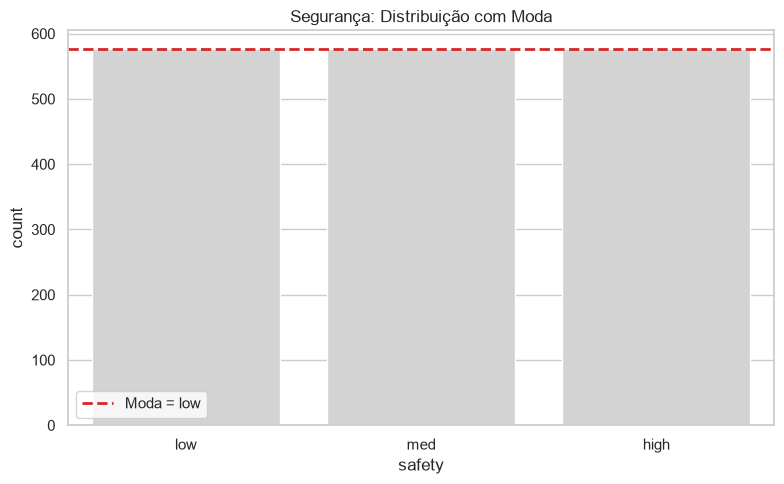

In [19]:
tendencia = pd.DataFrame([
    {
        "variavel": col,
        "moda": df[col].mode()[0],
        "mediana_cod": df[f"{col}_cod"].median(),
        "mediana_categoria": ORDEM_CATEGORIAS[col][int(np.floor(df[f"{col}_cod"].median()))],
    }
    for col in ORDEM_CATEGORIAS
]).set_index("variavel")

display(tendencia)

contagens_safety = df["safety"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="safety", order=ORDEM_CATEGORIAS["safety"], color=COR_NEUTRA)
plt.axhline(contagens_safety.max(), color=COR_ALERTA, linestyle="--", linewidth=2,
            label=f"Moda = {df['safety'].mode()[0]}")
plt.title("Segurança: Distribuição com Moda")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

Variância, desvio padrão e IQR também exigem valores numéricos. Usamos as versões codificadas (`*_cod`): a leitura não é "em unidades", e sim **quantos níveis de categoria** os carros variam naquele atributo. Um IQR de 2 em `buying_cod`, por exemplo, significa que a metade central dos carros se espalha por 2 níveis de preço.

In [20]:
dispersao = df[VARS_ORDINAIS_COD].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_ORDINAIS_COD].quantile(0.75) - df[VARS_ORDINAIS_COD].quantile(0.25)
dispersao.round(2)

,var,std,IQR
buying_cod,1.25,1.12,1.5
maint_cod,1.25,1.12,1.5
doors_cod,1.25,1.12,1.5
persons_cod,0.67,0.82,2.0
lug_boot_cod,0.67,0.82,2.0
safety_cod,0.67,0.82,2.0


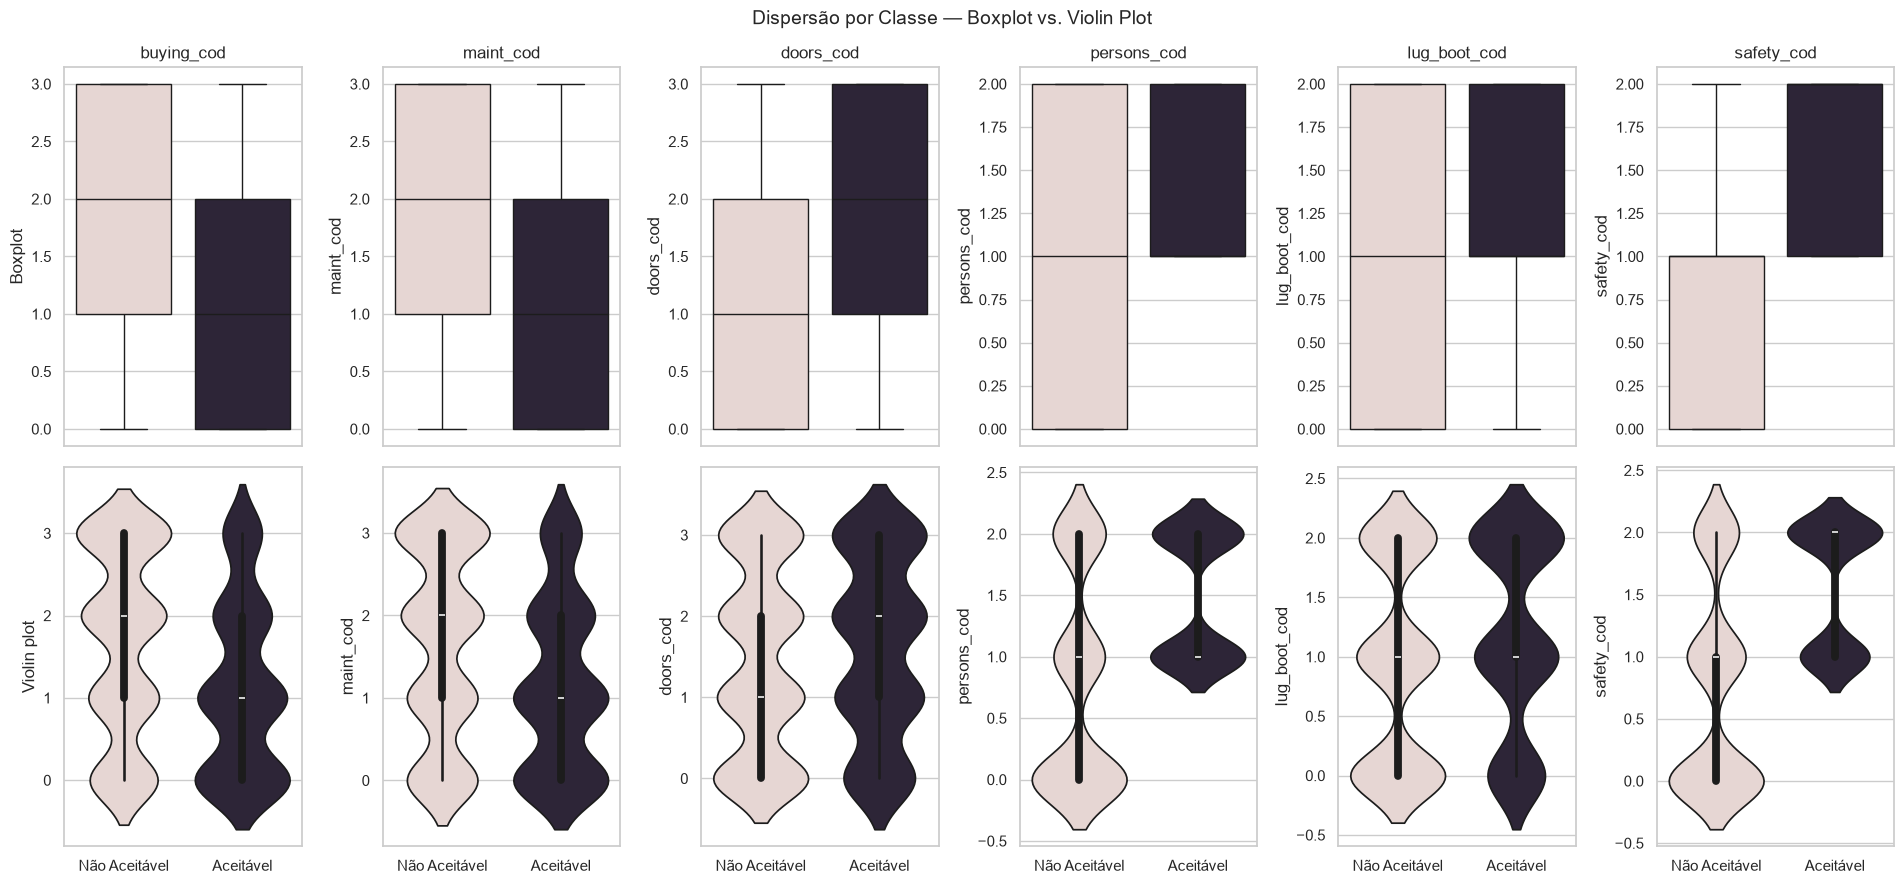

In [21]:
palette_classe = {"Não Aceitável": COR_CONTEXTO, "Aceitável": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_ORDINAIS_COD),
                         figsize=(3.2 * len(VARS_ORDINAIS_COD), 9), sharex="col")

for i, col in enumerate(VARS_ORDINAIS_COD):
    sns.boxplot(data=df, x="avaliacao", y=col, hue="avaliacao",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="avaliacao", y=col, hue="avaliacao",
                   palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Não Aceitável" e "Aceitável"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

**Cuidado na leitura:** com apenas 3 ou 4 níveis, o boxplot fica "achatado" (mediana colada em um quartil, poucos valores distintos). Ele ainda mostra deslocamento entre grupos, mas o violin plot e os painéis de contagem da seção anterior são mais informativos para variáveis ordinais curtas.

### 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), fechamos o ciclo verificando dois pontos: se há dados ausentes a tratar (não há, como vimos) e se existem "outliers" no sentido categórico — ou seja, categorias muito raras dentro de uma variável, que podem se comportar como pontos de atenção da mesma forma que outliers numéricos.

### Detecção de "Outliers" Categóricos (Categorias Raras)

Como não há variáveis quantitativas, a regra clássica do IQR não se aplica aqui. O equivalente para dados categóricos é identificar **categorias raras**: aquelas que aparecem com frequência muito menor que o esperado dentro de uma variável, e que merecem atenção (podem indicar erro de rotulagem, classe minoritária real, ou necessidade de agrupamento).

In [22]:
def categorias_raras(serie, limiar=0.05):
    freq = serie.value_counts(normalize=True)
    return freq[(freq > 0) & (freq < limiar)]

VARS_PARA_RARAS = VARS_QUALI + ["avaliacao_4"]

resumo_raras = {}
for col in VARS_PARA_RARAS:
    raras = categorias_raras(df[col])
    resumo_raras[col] = {
        "n_categorias_raras": len(raras),
        "categorias": list(raras.index),
        "frequencia_min (%)": round(raras.min() * 100, 2) if len(raras) > 0 else None,
    }

pd.DataFrame(resumo_raras).T

,n_categorias_raras,categorias,frequencia_min (%)
buying,0,[],None
maint,0,[],None
doors,0,[],None
persons,0,[],None
lug_boot,0,[],None
safety,0,[],None
avaliacao,0,[],None
avaliacao_4,2,"[good, vgood]",3.76


### Visualizando as Categorias Raras

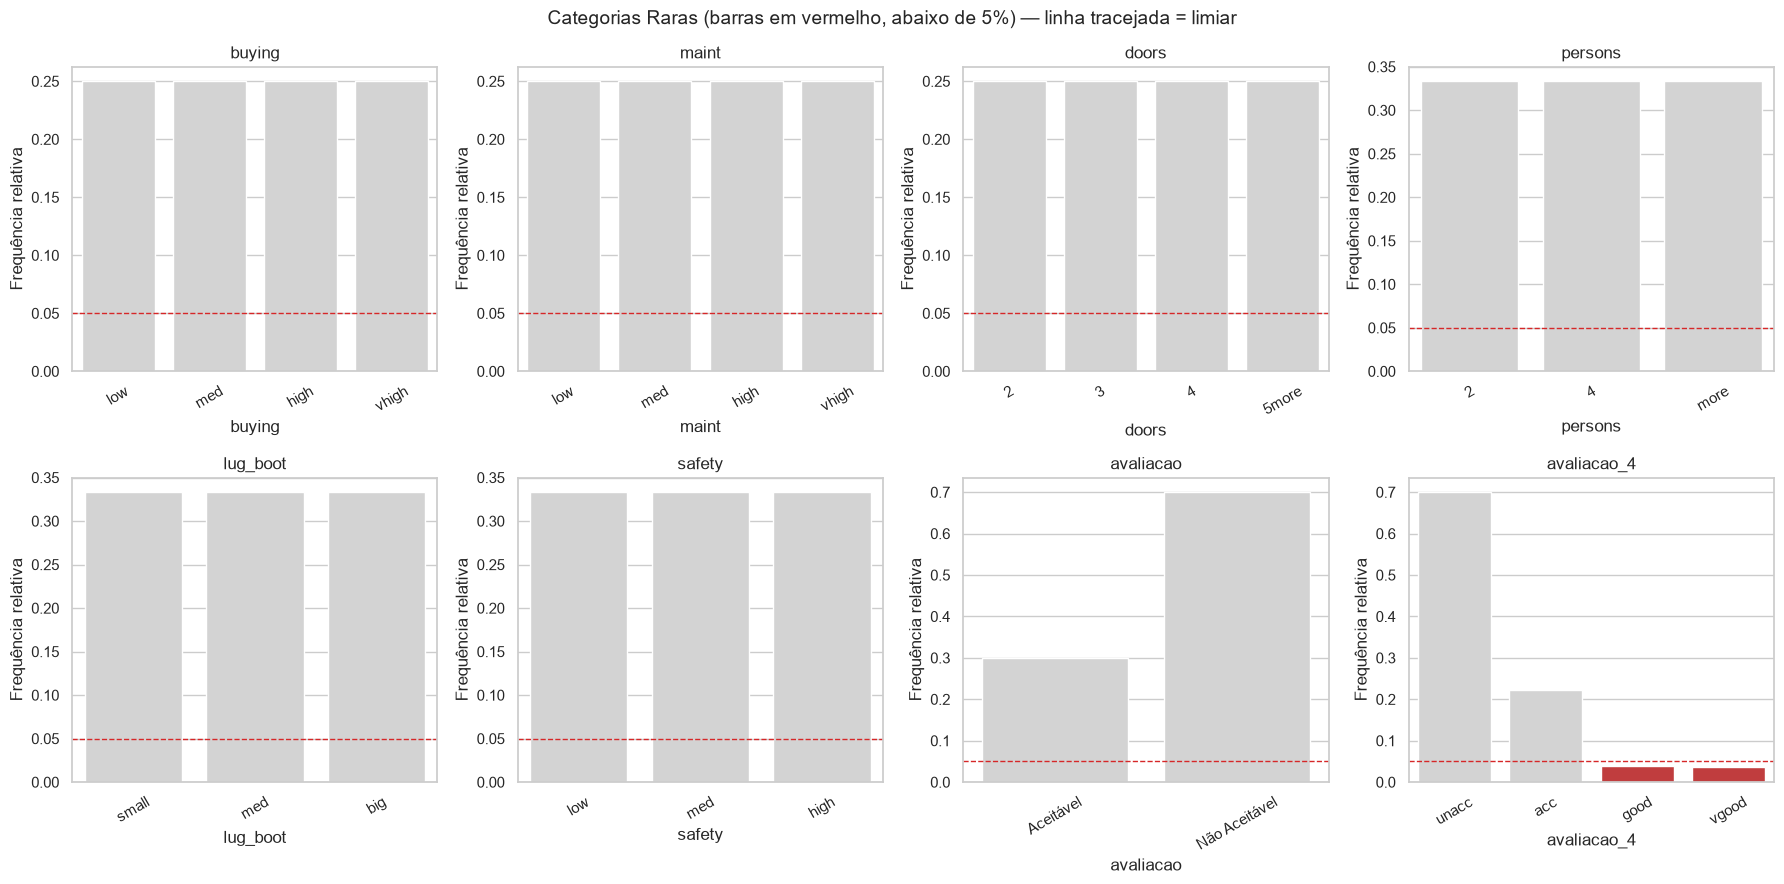

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.ravel()

limiar = 0.05
for i, col in enumerate(VARS_PARA_RARAS):
    freq = df[col].value_counts(normalize=True).sort_index()
    cores = [COR_ALERTA if v < limiar else COR_NEUTRA for v in freq.values]
    sns.barplot(x=freq.index.astype(str), y=freq.values, hue=freq.index.astype(str),
                palette=cores, legend=False, ax=axes[i])
    axes[i].axhline(limiar, color=COR_ALERTA, linestyle="--", linewidth=1)
    axes[i].set_title(col)
    axes[i].set_ylabel("Frequência relativa")
    axes[i].tick_params(axis="x", rotation=30)

for ax in axes[len(VARS_PARA_RARAS):]:
    ax.axis("off")

fig.suptitle("Categorias Raras (barras em vermelho, abaixo de 5%) — linha tracejada = limiar", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Aplicando ao nosso caso: nas **features** a tabela acima não encontrou nenhuma categoria abaixo de 5%, o que é esperado em um desenho fatorial completo. Já no **alvo** (`avaliacao_4`), `good` e `vgood` são categorias genuinamente raras. Elas parecem plausíveis no domínio (é natural que poucas combinações de carro sejam "muito boas"), violam alguma regra de negócio, ou parecem erro de rotulagem? A resposta define se o tratamento é manter, investigar ou corrigir.

**Decidindo o Tratamento dos Dados Ausentes**

Não se aplica neste caso — como confirmamos anteriormente, o dataset Car Evaluation não possui nenhum valor ausente. Essa etapa fica registrada aqui apenas para manter a estrutura do fluxo de EDA, servindo de lembrete de que essa decisão (imputar, remover, ou manter) só é necessária quando há valores ausentes de fato.

In [24]:
linhas_antes = df.shape[0]
df_antes = df.copy()
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")
print("Nenhuma remoção necessária: dataset não possui valores ausentes.")

Linhas antes: 1728 | Linhas depois: 1728 | Removidas: 0
Nenhuma remoção necessária: dataset não possui valores ausentes.


### Decidindo o Tratamento das Categorias Raras

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelas frequências encontradas (o dataset foi gerado combinando sistematicamente todas as categorias possíveis), a classificação mais provável é **"Estatístico"** — eventuais categorias raras são legítimas, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e reflete a estrutura do domínio — por exemplo, carros classificados como "vgood" costumam ser raros, e isso é esperado) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: modelos sensíveis a muitas categorias esparsas), **agrupar**.

Vamos manter as categorias originais por enquanto, mas ilustrar como ficaria um agrupamento em `buying` — útil caso, mais adiante em análises futuras, o número de categorias atrapalhe algum teste ou modelo.

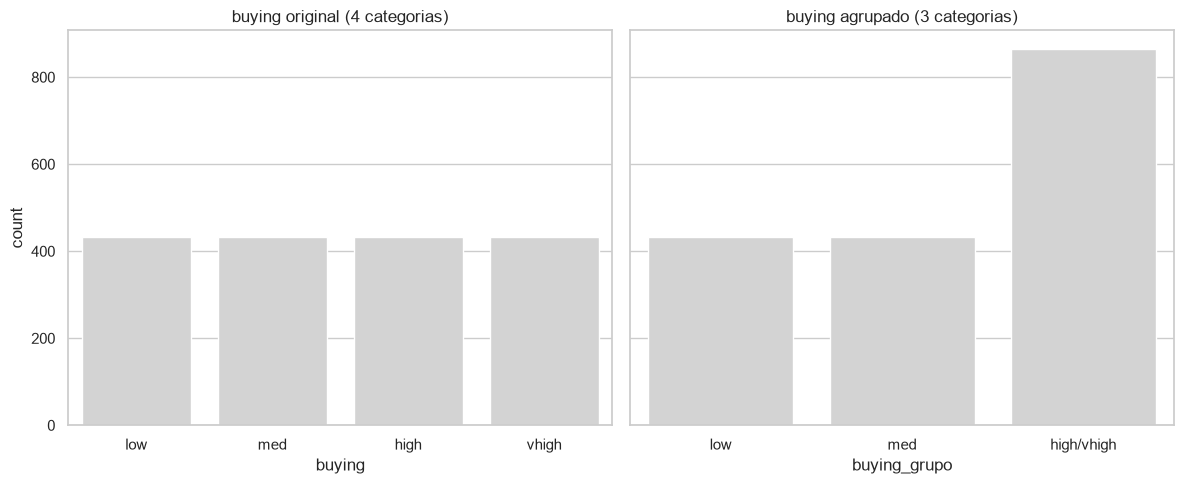

In [25]:
df["buying_grupo"] = pd.Categorical(
    df["buying"].astype(str).replace({"high": "high/vhigh", "vhigh": "high/vhigh"}),
    categories=["low", "med", "high/vhigh"], ordered=True,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.countplot(data=df, x="buying", order=ORDEM_CATEGORIAS["buying"], color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"buying original ({df['buying'].nunique()} categorias)")

sns.countplot(data=df, x="buying_grupo", order=["low", "med", "high/vhigh"], color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"buying agrupado ({df['buying_grupo'].nunique()} categorias)")

plt.tight_layout()
plt.show()

**Pra discutir:** o agrupamento simplificou a variável sem perder muita informação? Mantivemos `buying_grupo` só como demonstração e **não** vamos usá-la nas próximas seções. A ideia foi mostrar a opção caso o objetivo fosse, por exemplo, alimentar um modelo que sofre com muitas categorias esparsas.

**Nota:** nem toda categoria rara deve ser agrupada ou removida. Antes de decidir, classifiquem: é raro mas legítimo (manter), viola alguma regra de negócio (investigar antes de decidir), ou é claramente erro de digitação/rotulagem (corrigir ou remover)? No nosso caso, a raridade de `good`/`vgood` é informação real sobre o domínio — agrupá-las esconderia justamente o que torna um carro excepcional.

### 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: confirmamos que não havia ausentes a tratar e decidimos manter as categorias raras. Agora rodamos a mesma bateria de estatísticas (frequências) da Seção 3 para comparar diretamente com o "antes" — nesse caso, o "depois" deve ser idêntico, já que nenhuma linha foi removida ou alterada.

In [26]:
desc_depois = pd.DataFrame({
    col: df[col].value_counts(normalize=True).round(3) * 100
    for col in VARS_QUALI[:-1]
}).T

desc_depois.columns.name = "Categoria (%)"
desc_depois = desc_depois.style.background_gradient(cmap="Blues", axis=1).format(precision=1)
desc_depois

Categoria (%),2,3,4,5more,big,high,low,med,more,small,vhigh
buying,nan,nan,nan,nan,nan,25.0,25.0,25.0,nan,nan,25.0
maint,nan,nan,nan,nan,nan,25.0,25.0,25.0,nan,nan,25.0
doors,25.0,25.0,25.0,25.0,nan,nan,nan,nan,nan,nan,nan
persons,33.3,nan,33.3,nan,nan,nan,nan,nan,33.3,nan,nan
lug_boot,nan,nan,nan,nan,33.3,nan,nan,33.3,nan,33.3,nan
safety,nan,nan,nan,nan,nan,33.3,33.3,33.3,nan,nan,nan


### Comparando "antes" x "depois"

In [27]:
comparacoes = []
for col in VARS_QUALI:
    freq_antes = df_antes[col].value_counts(normalize=True) * 100
    freq_depois = df[col].value_counts(normalize=True) * 100
    for cat in freq_antes.index:
        comparacoes.append({
            "variavel": col,
            "categoria": cat,
            "freq_antes (%)": round(freq_antes.get(cat, 0), 2),
            "freq_depois (%)": round(freq_depois.get(cat, 0), 2),
        })

comparacao = pd.DataFrame(comparacoes)
comparacao["delta (%)"] = (comparacao["freq_depois (%)"] - comparacao["freq_antes (%)"]).round(3)
comparacao

,variavel,categoria,freq_antes (%),freq_depois (%),delta (%)
0,buying,low,25.00,25.00,0.0
1,buying,med,25.00,25.00,0.0
2,buying,high,25.00,25.00,0.0
3,buying,vhigh,25.00,25.00,0.0
4,maint,low,25.00,25.00,0.0
5,maint,med,25.00,25.00,0.0
6,maint,high,25.00,25.00,0.0
7,maint,vhigh,25.00,25.00,0.0
8,doors,2,25.00,25.00,0.0
9,doors,3,25.00,25.00,0.0


**Pra discutir:** os valores mudaram? Fazia sentido esperar diferença, considerando que não removemos nem alteramos nenhuma linha? Esse resultado (nenhuma mudança) é, na verdade, uma confirmação de que o dataset já estava íntegro desde o início — não um sinal de que a etapa de tratamento não foi feita corretamente.

**As categorias de `buying` ainda rejeitam uniformidade?**

Vamos rodar o mesmo teste Qui-Quadrado da Seção 3, agora confirmando que os dados continuam os mesmos.

In [28]:
freq_obs_depois = df["buying"].value_counts().sort_index()
stat_chi2_depois, p_valor_chi2_depois = chisquare(freq_obs_depois)

print(f"Qui-Quadrado (antes) — buying: estatística={stat_chi2:.4f}, p-valor={p_valor_chi2:.4g}")
print(f"Qui-Quadrado (depois) — buying: estatística={stat_chi2_depois:.4f}, p-valor={p_valor_chi2_depois:.4g}")

Qui-Quadrado (antes) — buying: estatística=0.0000, p-valor=1
Qui-Quadrado (depois) — buying: estatística=0.0000, p-valor=1


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção (`buying` e `safety`), comparando a versão original (`df_antes`) com a "tratada" (`df`).

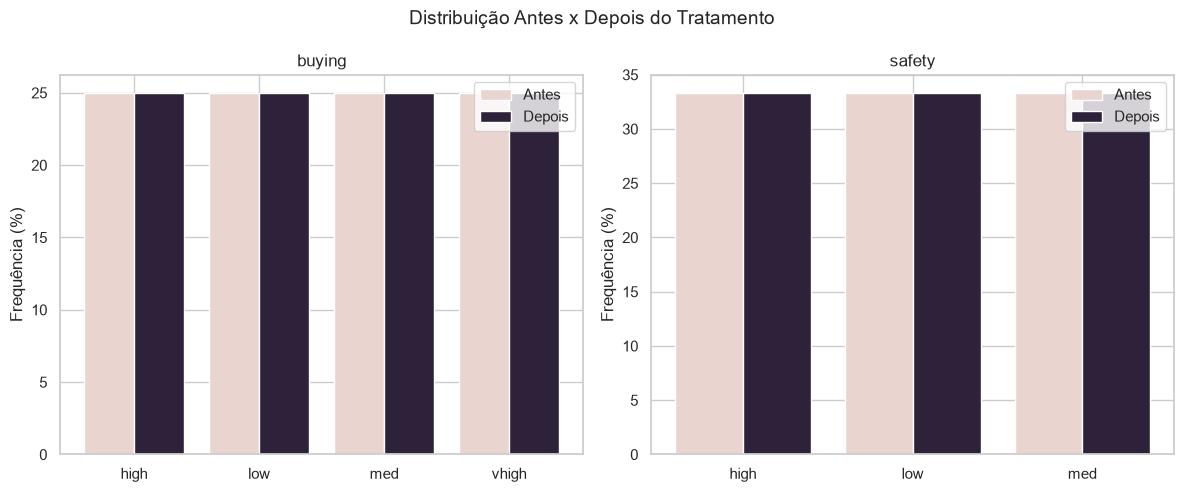

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["buying", "safety"]):
    ordem = sorted(df[col].unique())
    freq_antes = df_antes[col].value_counts(normalize=True).reindex(ordem) * 100
    freq_depois = df[col].value_counts(normalize=True).reindex(ordem) * 100

    x = range(len(ordem))
    ax.bar([p - 0.2 for p in x], freq_antes.values, width=0.4, color=COR_CONTEXTO, label="Antes")
    ax.bar([p + 0.2 for p in x], freq_depois.values, width=0.4, color=COR_DESTAQUE, label="Depois")
    ax.set_xticks(list(x))
    ax.set_xticklabels(ordem)
    ax.set_title(col)
    ax.set_ylabel("Frequência (%)")
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que não removemos nenhuma linha e não alteramos nenhuma categoria.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível. Essa checagem "antes x depois" é o que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [30]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- buying ---
        absoluta  relativa
buying                    
low          432      0.25
med          432      0.25
high         432      0.25
vhigh        432      0.25

--- maint ---
       absoluta  relativa
maint                    
low         432      0.25
med         432      0.25
high        432      0.25
vhigh       432      0.25

--- doors ---
       absoluta  relativa
doors                    
2           432      0.25
3           432      0.25
4           432      0.25
5more       432      0.25

--- persons ---
         absoluta  relativa
persons                    
2             576     0.333
4             576     0.333
more          576     0.333

--- lug_boot ---
          absoluta  relativa
lug_boot                    
small          576     0.333
med            576     0.333
big            576     0.333

--- safety ---
        absoluta  relativa
safety                    
low          576     0.333
med          576     0.333
high         576     0.333

--- aval

#### Visualizando as frequências

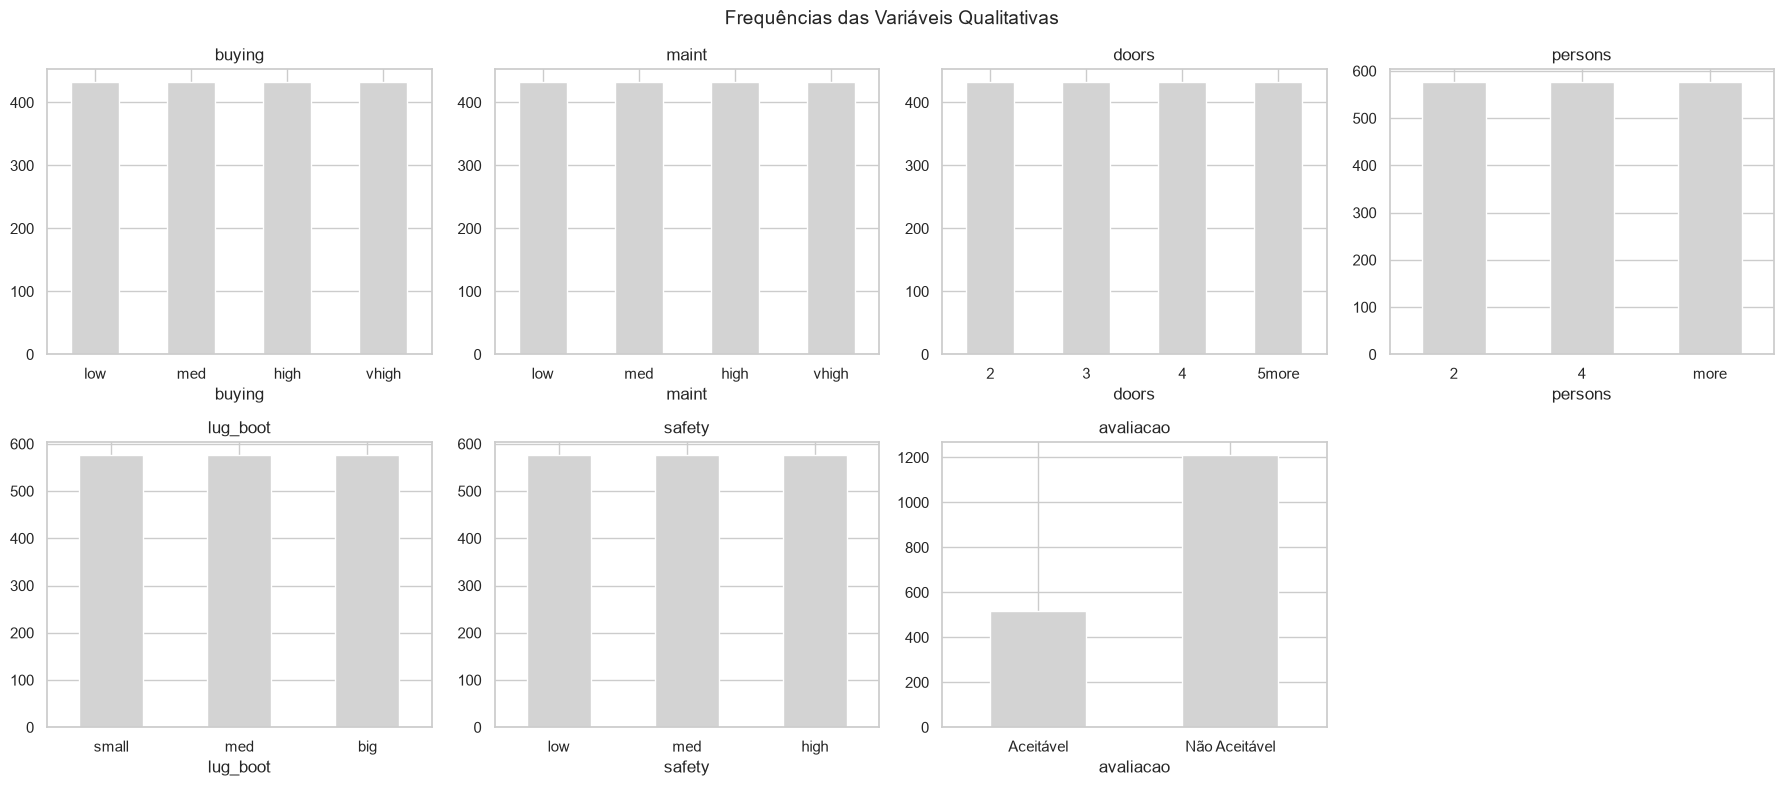

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o alvo binário `avaliacao` e também o alvo original de 4 classes (`avaliacao_4`), que é onde o desbalanceamento realmente aparece.

In [32]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    contagens = contagens[contagens > 0]
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["avaliacao_4"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
buying,4.0,1.00,1.000
maint,4.0,1.00,1.000
doors,4.0,1.00,1.000
persons,3.0,1.00,1.000
lug_boot,3.0,1.00,1.000
safety,3.0,1.00,1.000
avaliacao,2.0,2.34,0.881
avaliacao_4,4.0,18.62,0.603


**Pra discutir:** as 6 features devem aparecer com entropia igual (ou muito próxima) a 1 e razão de desbalanceamento igual a 1 — consequência direta do desenho fatorial completo. Todo o desbalanceamento está concentrado no alvo.

Olhem os dois alvos lado a lado: `avaliacao` (binário) e `avaliacao_4` (4 classes). Qual dos dois está mais desbalanceado, e por quê? Isso importa na prática: com classes minoritárias muito pequenas, acurácia deixa de ser uma métrica informativa e a divisão treino/teste precisa ser estratificada.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo `avaliacao`.

#### Ordinal x Ordinal — Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Aqui a escolha é mais direta do que na demonstração: nossas variáveis são **ordinais**, não contínuas. Pearson pressupõe intervalos iguais entre os valores, e não temos garantia de que a distância de `low` para `med` seja a mesma de `med` para `high` — é uma ordem, não uma escala. Por isso **Spearman e Kendall são os apropriados** (ambos trabalham com postos), e o Kendall costuma ser preferido quando há muitos empates, que é exatamente o nosso caso com apenas 3–4 níveis. Calculamos as três para comparar.

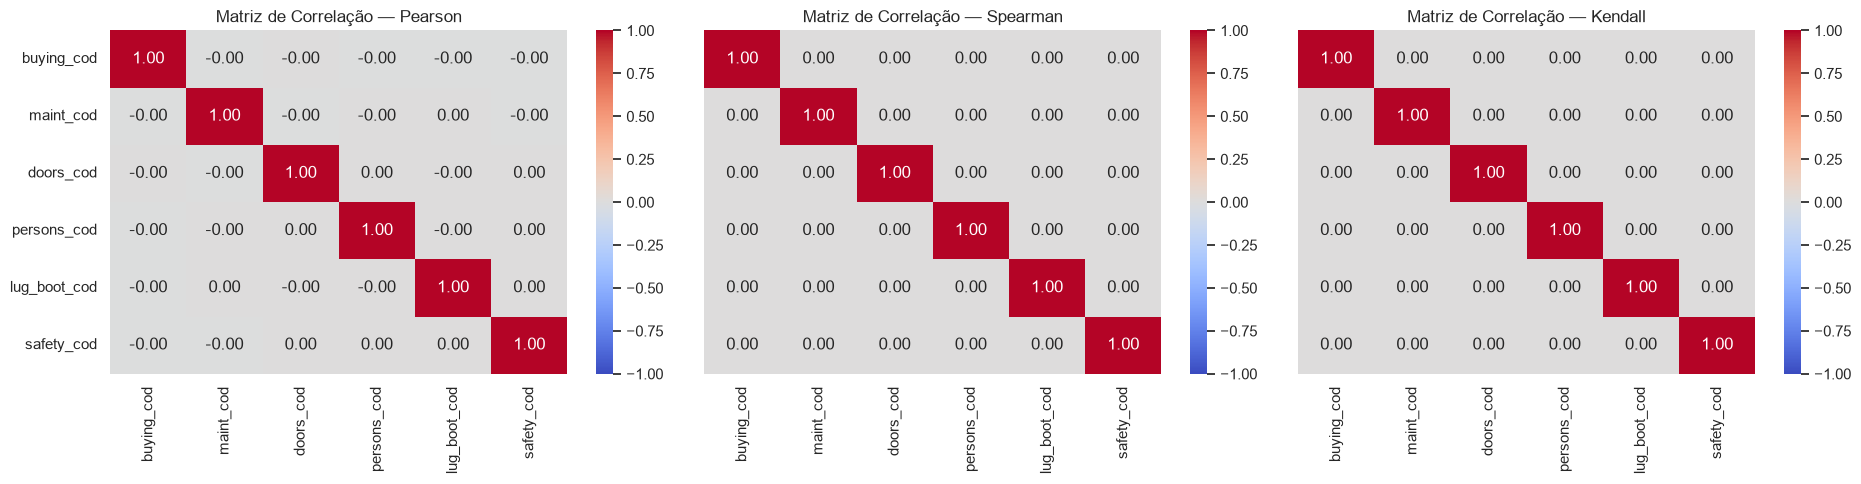

In [33]:
corr_pearson = df[VARS_ORDINAIS_COD].corr(method="pearson")
corr_spearman = df[VARS_ORDINAIS_COD].corr(method="spearman")
corr_kendall = df[VARS_ORDINAIS_COD].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

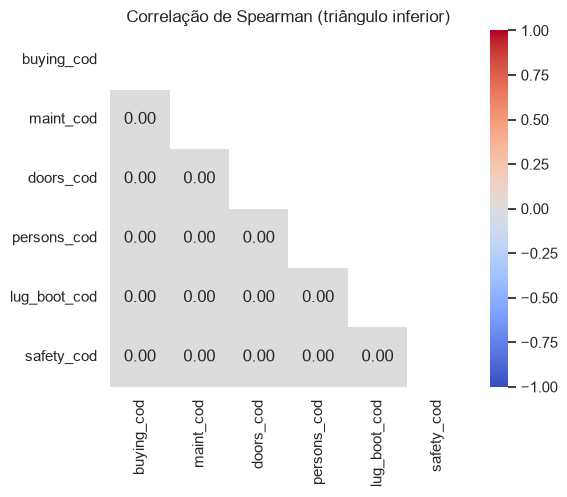

In [34]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, vmin=-1, vmax=1)
plt.title("Correlação de Spearman (triângulo inferior)")
plt.grid(False)
plt.tight_layout()
plt.show()

**Pra discutir:** o resultado aqui é chamativo — **todas** as correlações fora da diagonal devem dar praticamente zero, nos três métodos.

Isso não é um defeito da análise, é uma consequência do desenho do dataset: como ele contém **todas** as combinações possíveis de atributos exatamente uma vez, cada variável é independente das outras por construção. Não existe multicolinearidade a tratar e nenhuma variável é redundante em relação a outra — toda a informação útil está na relação de cada feature com o **alvo**, não entre features.

Compare com o Heart Disease da demonstração, onde as variáveis são medidas do mesmo paciente e naturalmente se correlacionam. A pergunta que fica: em qual dos dois cenários uma matriz de correlação entre preditoras é mais informativa, e por quê?

#### Dispersão entre duas variáveis ordinais

Escolhemos `buying` x `safety` por um motivo de domínio, não só estatístico: preço e segurança são o trade-off clássico na escolha de um carro, o que torna esse par um bom candidato pra visualizar como as duas classes se distribuem.

**Nota sobre a técnica:** um scatter plot puro de duas variáveis ordinais mostraria apenas 12 pontos sobrepostos (4 níveis × 3 níveis), escondendo a densidade. A solução padrão é adicionar **jitter** (um deslocamento aleatório pequeno) para separar visualmente os pontos empilhados.

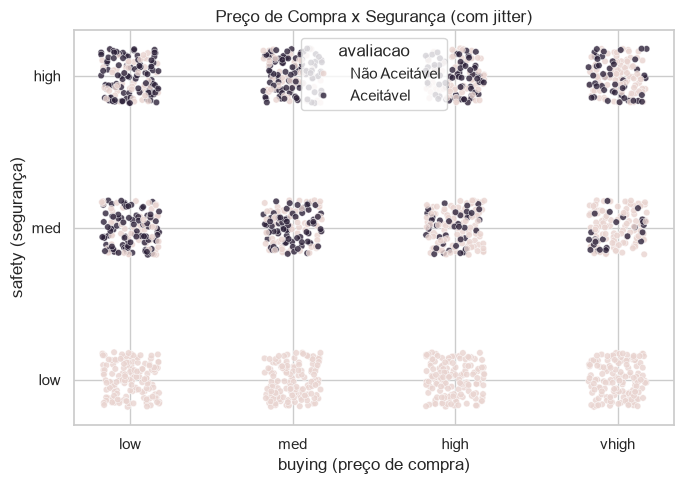

In [35]:
rng = np.random.default_rng(42)
plot_df = df.copy()
plot_df["buying_jit"] = plot_df["buying_cod"] + rng.uniform(-0.18, 0.18, len(plot_df))
plot_df["safety_jit"] = plot_df["safety_cod"] + rng.uniform(-0.18, 0.18, len(plot_df))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_df, x="buying_jit", y="safety_jit", hue="avaliacao",
                palette={"Não Aceitável": COR_CONTEXTO, "Aceitável": COR_DESTAQUE},
                alpha=0.8, s=22)
plt.xticks(range(len(ORDEM_CATEGORIAS["buying"])), ORDEM_CATEGORIAS["buying"])
plt.yticks(range(len(ORDEM_CATEGORIAS["safety"])), ORDEM_CATEGORIAS["safety"])
plt.title("Preço de Compra x Segurança (com jitter)")
plt.xlabel("buying (preço de compra)")
plt.ylabel("safety (segurança)")
plt.tight_layout()
plt.show()

**Pra discutir:** as duas classes ocupam regiões diferentes do gráfico, ou estão misturadas? Repare na faixa de `safety = low`: ela parece conter carros aceitáveis? Se uma faixa inteira do eixo Y for monocromática, isso significa que aquele atributo sozinho já decide o alvo naquela região — informação valiosa antes de qualquer modelo.

#### Ordinal x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo — e, mais que isso, assumem uma variável **contínua**.

Nossas variáveis são ordinais com 3–4 níveis: não são normais nem contínuas, então os equivalentes **não-paramétricos** são os corretos aqui — **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Calculamos os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [36]:
resultados_comparacao = []
for col in VARS_ORDINAIS_COD:
    grupo_nao_aceitavel = df.loc[df["avaliacao"] == "Não Aceitável", col]
    grupo_aceitavel = df.loc[df["avaliacao"] == "Aceitável", col]

    stat_t, p_t = stats.ttest_ind(grupo_nao_aceitavel, grupo_aceitavel, equal_var=False)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao_aceitavel, grupo_aceitavel)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
buying_cod,0.00000,0.00000,True
maint_cod,0.00000,0.00000,True
doors_cod,0.00892,0.00982,True
persons_cod,0.00000,0.00000,True
lug_boot_cod,0.00000,0.00000,True
safety_cod,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar — é o que respeita a premissa que de fato temos (dados ordinais, não normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test sobre variáveis com 3 níveis, sem essa ressalva, seria estatisticamente inconsistente.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

É aqui que o `avaliacao_4` que guardamos volta a ser útil: o alvo original tem 4 categorias (`unacc`, `acc`, `good`, `vgood`). Comparamos `safety_cod` entre essas 4 classes, calculando a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico) lado a lado.

ANOVA          — safety entre as 4 classes: estatística=167.756, p-valor=2.0573e-95
Kruskal-Wallis — safety entre as 4 classes: estatística=390.229, p-valor=2.8938e-84


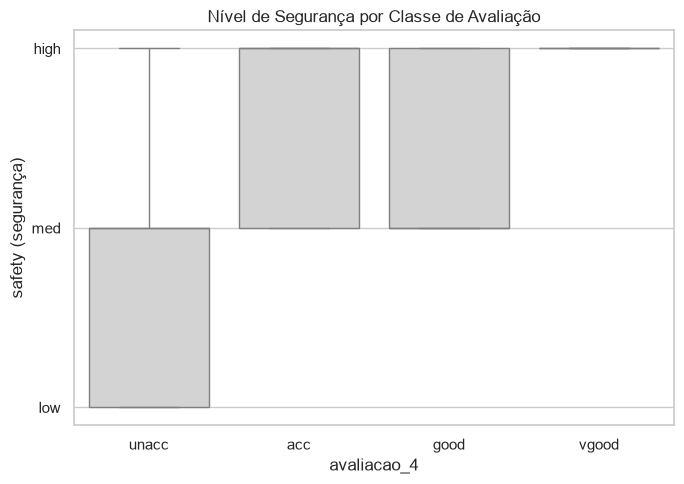

In [37]:
grupos_safety = [g["safety_cod"].values for _, g in df.groupby("avaliacao_4", observed=True)]

stat_anova, p_anova = stats.f_oneway(*grupos_safety)
stat_kw, p_kw = stats.kruskal(*grupos_safety)

print(f"ANOVA          — safety entre as 4 classes: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — safety entre as 4 classes: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="avaliacao_4", y="safety_cod", color=COR_NEUTRA)
plt.yticks(range(len(ORDEM_CATEGORIAS["safety"])), ORDEM_CATEGORIAS["safety"])
plt.title("Nível de Segurança por Classe de Avaliação")
plt.xlabel("avaliacao_4")
plt.ylabel("safety (segurança)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença de `safety` entre pelo menos uma das 4 classes? Como `safety_cod` é ordinal e tem apenas 3 níveis, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal — a ANOVA fica só como contraste.

Atenção também ao que o teste **não** diz: ele aponta que existe diferença entre as classes, mas não diz *entre quais*. Para isso seriam necessários testes post-hoc (ex: Dunn com correção para múltiplas comparações).

#### Qualitativa x Qualitativa — Qui-Quadrado de Independência

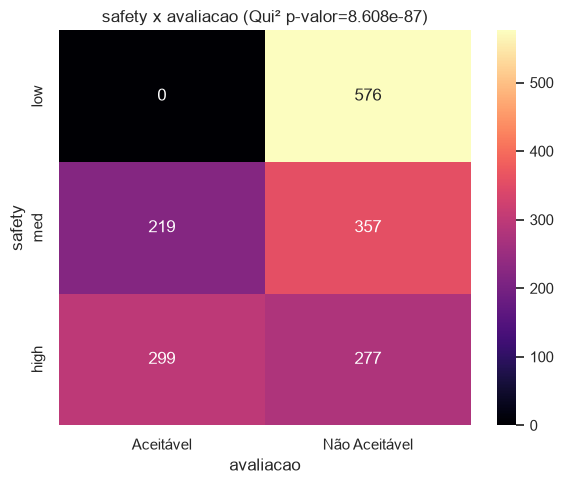

In [38]:
contingencia_safety = pd.crosstab(df["safety"], df["avaliacao"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_safety)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_safety, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"safety x avaliacao (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `safety` e `avaliacao` são independentes, ou há associação estatisticamente significativa entre elas?

Repare no mapa de calor: a linha de `safety = low` tem alguma célula na coluna "Aceitável"? Quando uma célula da tabela de contingência é zero, a associação deixa de ser apenas estatística e passa a ser **determinística** — aquele valor do atributo, por si só, já decide o desfecho.

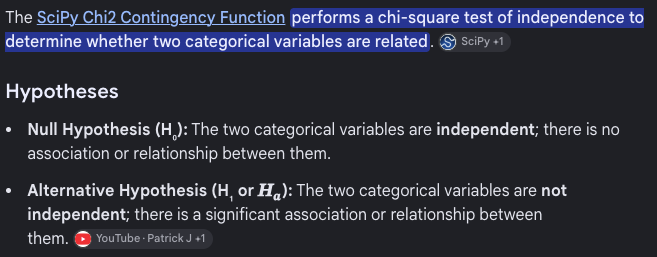

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos?

**Uma ressalva importante de honestidade metodológica:** o Car Evaluation **não contém atributos sensíveis** — não há pessoas nele, logo não há sexo, raça, idade ou renda a proteger. Uma análise de fairness no sentido estrito não se aplica aqui, e forçar essa leitura seria incorreto.

O que podemos fazer é exercitar a **mecânica** da análise, que é idêntica: escolher atributos que definem subgrupos (usamos `persons`, capacidade de passageiros, e `lug_boot`, tamanho do porta-malas) e verificar se a proporção do desfecho varia entre eles. Em um dataset com pessoas, esses mesmos gráficos e testes seriam aplicados aos atributos protegidos, e a interpretação passaria a ter peso ético — é essa transposição que vale reter.

In [39]:
print("Desbalanceamento — persons (capacidade de passageiros):")
print(metrica_desbalanceamento(df["persons"]))
print("\nDesbalanceamento — lug_boot (tamanho do porta-malas):")
print(metrica_desbalanceamento(df["lug_boot"]))

Desbalanceamento — persons (capacidade de passageiros):
n_classes                 3.0
razao_desbalanceamento    1.0
entropia_normalizada      1.0
dtype: float64

Desbalanceamento — lug_boot (tamanho do porta-malas):
n_classes                 3.0
razao_desbalanceamento    1.0
entropia_normalizada      1.0
dtype: float64


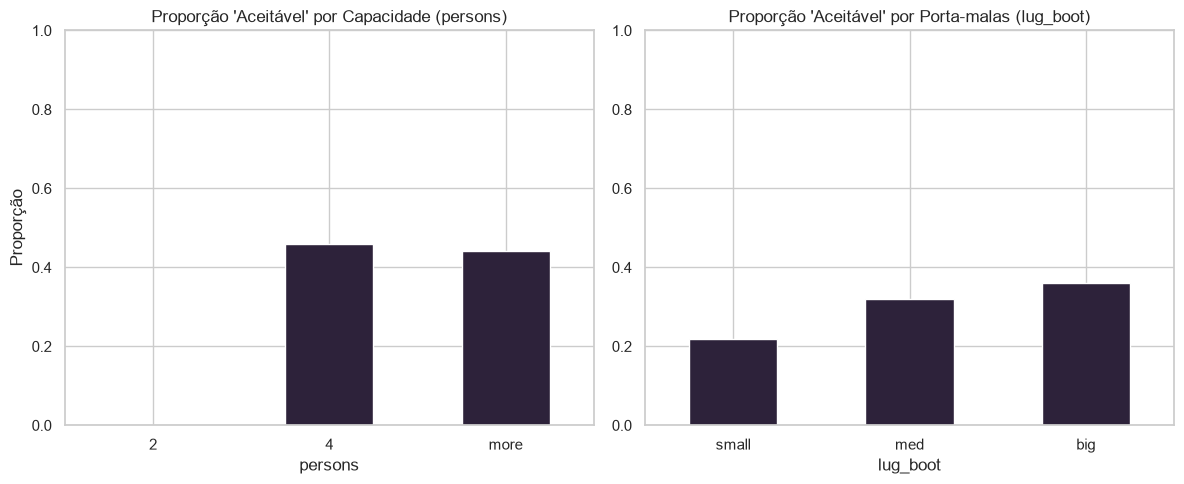

In [40]:
prop_por_persons = pd.crosstab(df["persons"], df["avaliacao"], normalize="index").round(3)
prop_por_lug = pd.crosstab(df["lug_boot"], df["avaliacao"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_persons["Aceitável"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Aceitável' por Capacidade (persons)")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_lug["Aceitável"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Aceitável' por Porta-malas (lug_boot)")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de carros aceitáveis varia bastante entre os níveis de `persons` ou de `lug_boot`? Repare em `persons = 2`: se a barra for zero, significa que nenhum carro de 2 lugares foi classificado como aceitável — uma **regra determinística** embutida no sistema especialista que gerou os dados, não uma tendência estatística.

Essa distinção é o ponto da seção. Aqui a disparidade entre subgrupos tem uma causa conhecida e documentada (a regra do modelo DEX). Em um dataset com pessoas, uma disparidade equivalente teria causa ambígua: poderia ser um fator real, um viés de quem entrou na amostra, ou as duas coisas. A pergunta "a distribuição do desfecho é uniforme entre subgrupos?" é o ponto de partida — a resposta útil vem de investigar *por que* ela não é.

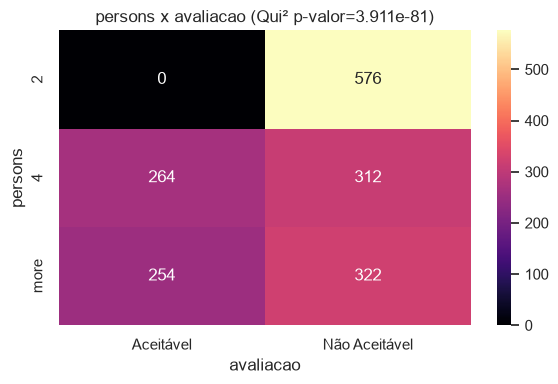

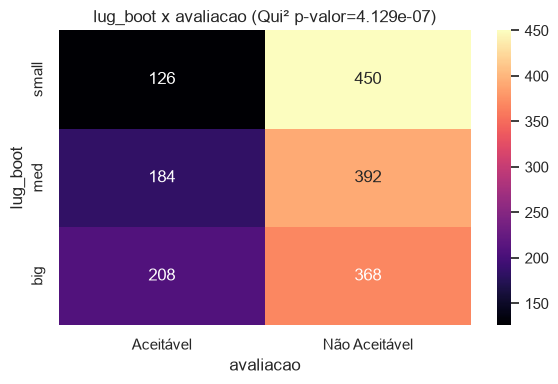

In [41]:
for atributo in ["persons", "lug_boot"]:
    contingencia = pd.crosstab(df[atributo], df["avaliacao"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x avaliacao (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre `persons`/`lug_boot` e o desfecho? Lembrando que, mesmo significativa, a associação não diz *por que* ela existe.

No nosso caso sabemos a causa (as regras do sistema especialista), o que é um luxo raro. Em dados reais a causa quase nunca é conhecida, e é aí que mora o risco: um teste estatístico aponta *que* existe associação, não *a causa* dela. Essa distinção é o núcleo de qualquer discussão séria de fairness — e a razão pela qual conhecimento de domínio não é opcional na EDA.

#### Outliers bivariados

Na demonstração, a busca era por um ponto que não parecia extremo em nenhuma variável isolada, mas que forma uma combinação improvável quando olhamos duas variáveis juntas. O equivalente para dados categóricos é a **combinação rara**: um par de categorias que aparece muito menos que o esperado.

Também vale olhar o desfecho por combinação — uma célula com comportamento muito diferente das vizinhas é o análogo bivariado de um ponto de atenção.

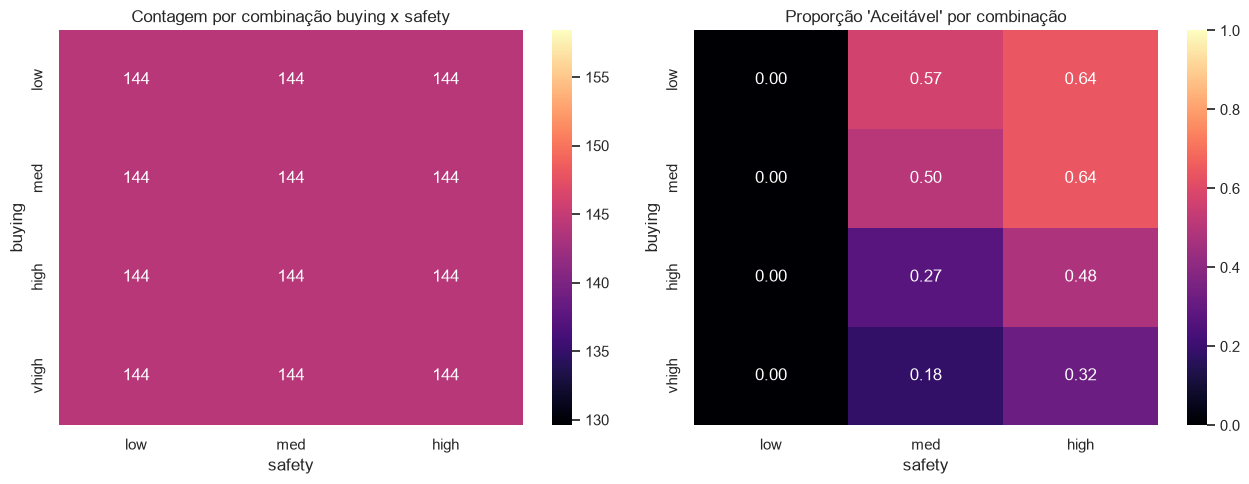

In [42]:
combo_contagem = pd.crosstab(df["buying"], df["safety"])
combo_aceitavel = pd.crosstab(df["buying"], df["safety"],
                              values=(df["avaliacao"] == "Aceitável").astype(int),
                              aggfunc="mean").round(2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(combo_contagem, annot=True, fmt="d", cmap="magma", ax=axes[0])
axes[0].set_title("Contagem por combinação buying x safety")

sns.heatmap(combo_aceitavel, annot=True, fmt=".2f", cmap="magma", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Proporção 'Aceitável' por combinação")

plt.tight_layout()
plt.show()

**Pra discutir:** no painel da esquerda, alguma combinação de `buying` x `safety` é rara ou inexistente? Em um desenho fatorial completo a resposta esperada é não — todas as células devem ter a mesma contagem, e isso confirma que o dataset cobre o espaço de atributos uniformemente.

O painel da direita é onde a informação está: as proporções variam entre células? Se a linha de `safety = low` for inteira zero enquanto outras células chegam perto de 1, temos uma interação clara entre os dois atributos e o alvo — algo que nenhuma análise univariada mostraria.

#### Análise Multivariada

##### Matriz de Correlação

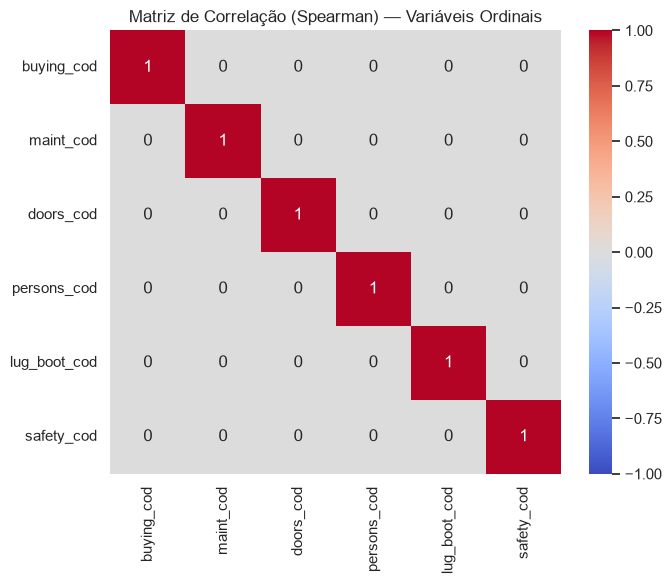

In [43]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_ORDINAIS_COD].corr(method="spearman"), annot=True,
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Ordinais")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis? Como vimos na seção anterior, aqui a resposta esperada é que **todas** fiquem na faixa "fraca" (próximas de zero) — consequência do desenho fatorial completo, não de uma falha na análise.

##### Correlograma

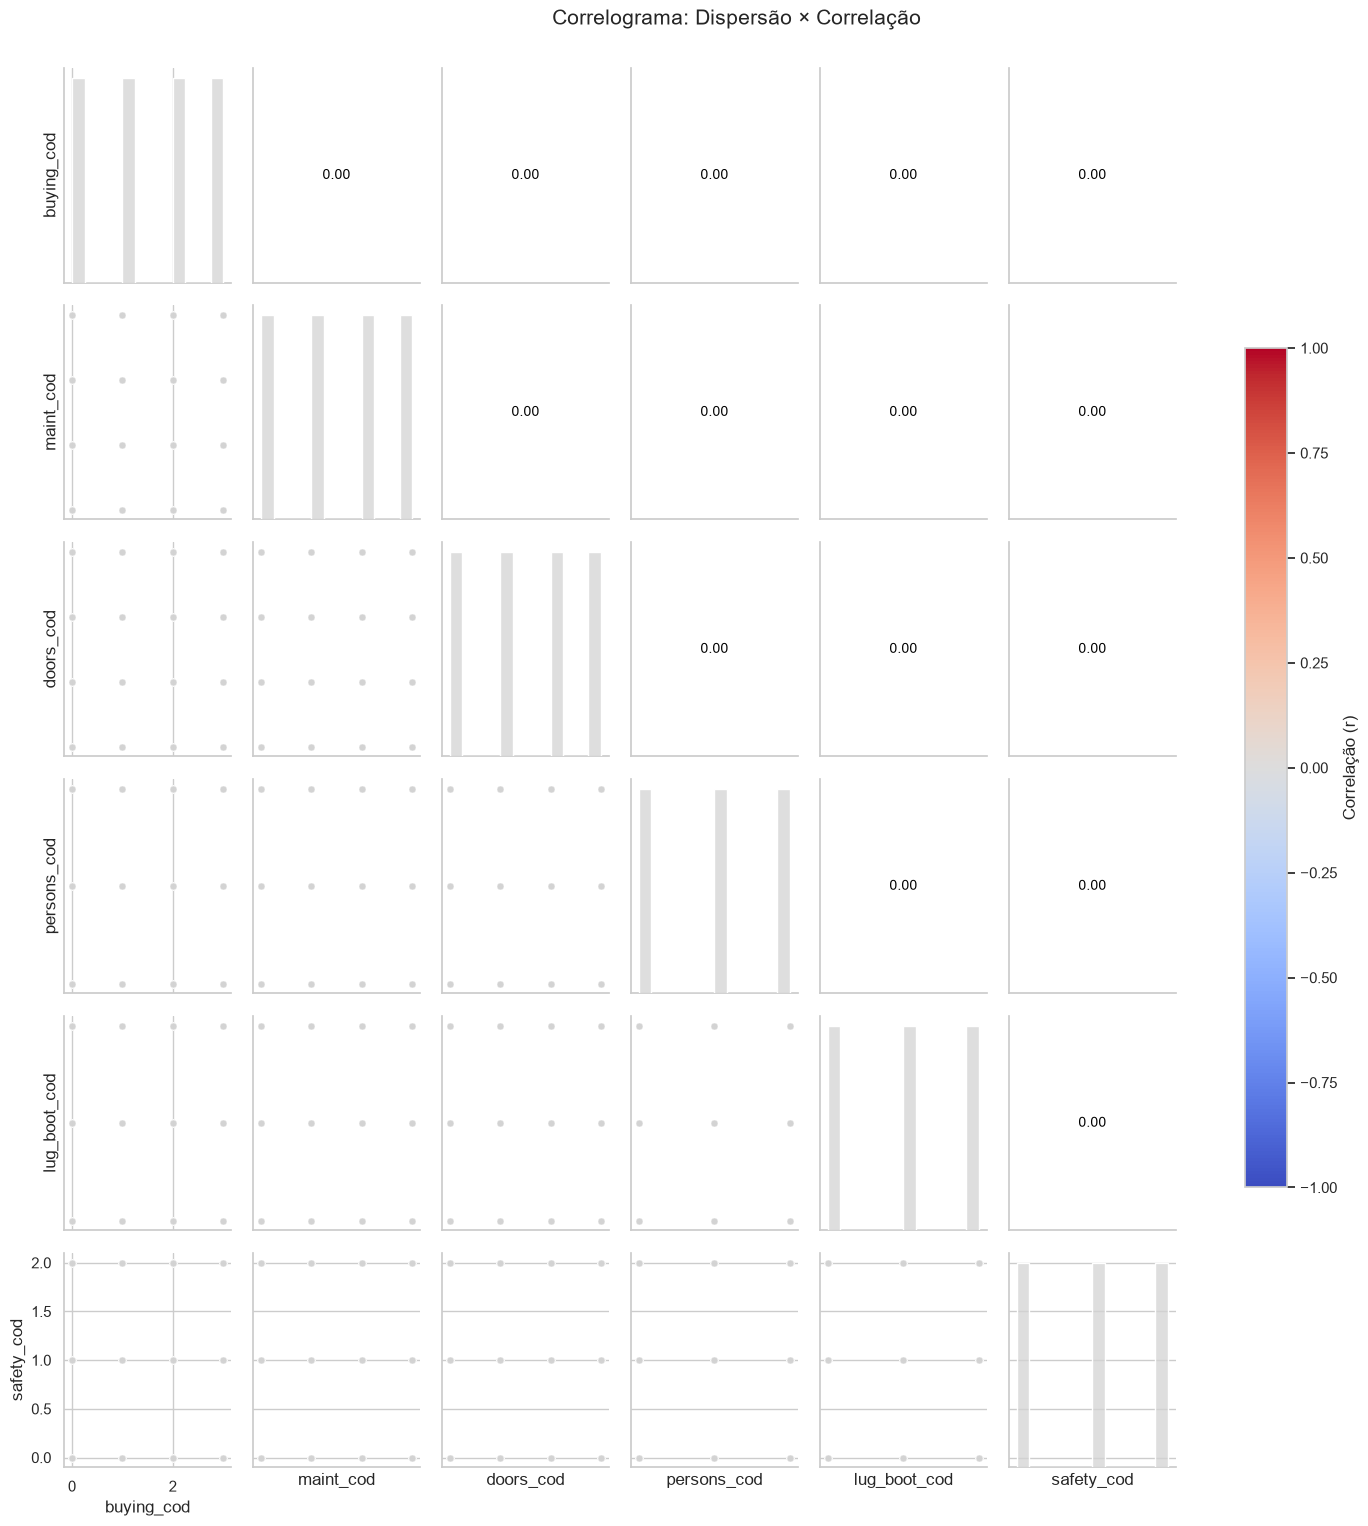

In [44]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_ORDINAIS_COD], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=False)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Síntese: Principais Conclusões

**1. O dataset é sintético e está completo.**
O dataset possui 1.728 linhas e 7 colunas, sem valores ausentes ou registros duplicados. Isso acontece porque o Car Evaluation foi criado a partir de todas as combinações possíveis dos seus 6 atributos, resultando nas 1.728 combinações. Por isso, algumas etapas comuns de uma análise exploratória, como tratamento de valores faltantes ou remoção de registros, não foram necessárias neste caso.

**2. Todas as variáveis são categóricas e possuem uma ordem.**
As variáveis do dataset não são contínuas, mas sim categóricas ordinais. Por esse motivo, medidas como média, assimetria, curtose e testes como Shapiro-Wilk não são adequados para esse conjunto de dados. A análise foi feita principalmente utilizando frequências, proporções e testes de associação. Quando a ordem das categorias permitia, também foram utilizadas medidas como mediana e correlação de Spearman e Kendall.

**3. As variáveis de entrada estão balanceadas, mas o mesmo não acontece com o resultado.**
As categorias das variáveis preditoras aparecem de forma equilibrada, com frequências de 25% ou 33,3%, dependendo da quantidade de categorias. Já a variável alvo apresenta uma distribuição bem diferente, com uma concentração maior na categoria de carros considerados inaceitáveis. Nas classes `good` e `vgood`, por exemplo, a quantidade de registros é bem menor.

**4. As variáveis de entrada são independentes entre si.**
As correlações entre as variáveis preditoras foram iguais a zero nas análises realizadas com Pearson, Spearman e Kendall. Isso faz sentido porque o dataset foi construído considerando todas as combinações possíveis entre os atributos. Dessa forma, não foi identificada uma relação de dependência ou redundância significativa entre as features. A informação mais importante aparece quando essas variáveis são analisadas em conjunto com a variável alvo.

**5. A análise entre as variáveis mostra regras bem definidas.**
Ao cruzar as variáveis com o resultado, principalmente `safety` e `persons`, foi possível perceber relações muito fortes com a classificação final. Algumas combinações apresentam uma proporção muito baixa ou até zero de carros considerados aceitáveis. Nesse caso, não se trata apenas de uma tendência encontrada nos dados, mas de regras que fazem parte da própria lógica utilizada para gerar o dataset.

**Implicação prática:**
Caso o dataset seja utilizado posteriormente para criar um modelo de classificação, os principais cuidados não estão relacionados à limpeza dos dados, já que eles estão completos e estruturados. Os pontos mais importantes são o **desbalanceamento da variável alvo**, que torna interessante utilizar divisão estratificada e métricas além da acurácia, e o fato de as features serem **ordinais**, o que deve ser considerado na escolha da forma de codificação das variáveis.

## Declaração de Uso de IA

**Ferramenta utilizada:** Claude

**Para o que foi utilizada:**

* Adaptação do notebook utilizado na demonstração (Heart Disease, `id=45`) para o dataset escolhido (Car Evaluation, `id=19`), incluindo a alteração da forma de carregamento dos dados com `ucimlrepo` e a binarização da variável alvo.
* Adaptação das técnicas utilizadas na demonstração para o tipo de dado presente no dataset, que é composto por variáveis categóricas ordinais. Por exemplo, o Shapiro-Wilk foi substituído pelo Qui-Quadrado de aderência, o histograma por gráficos de barras de frequência e a análise de outliers por IQR pela análise de categorias raras.
* Reescrita e adaptação dos textos de discussão e das interpretações para o contexto de avaliação de carros.
* Identificação e correção de alguns erros durante a execução do notebook, como `NameError` por variável não definida, `IndexError` em listas vazias e problemas ao utilizar `replace` em colunas do tipo `Categorical`.

**O que foi aproveitado:**

* A estrutura geral das adaptações e a utilização dos testes não paramétricos, após conferir esses conceitos na bibliografia disponibilizada na aula.
* A ideia de centralizar a codificação ordinal em `ORDEM_CATEGORIAS`, evitando repetir o mesmo código em diferentes partes do notebook.

**O que foi modificado:**

* As conclusões da síntese foram reescritas com minhas próprias palavras, depois de analisar e conferir os resultados obtidos no notebook e formatadas com IA.

**O que foi rejeitado e por quê:**

* A sugestão inicial de aplicar ECDF diretamente às variáveis categóricas. Como a técnica trabalha com valores que podem ser ordenados, optei por utilizar a versão com as categorias previamente codificadas.
* A análise de fairness seguindo exatamente o modelo da demonstração. Como o dataset não possui atributos sensíveis, mantive apenas a mecânica da análise e deixei essa limitação explícita.


---
> 🆕 **NOVA SEÇÃO (não estava no notebook da aula)** — as 4 células abaixo (esta, mais 3) servem apenas para salvar os datasets em disco.

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset:

- `data/raw/dataset.csv`: o dataset **original**, como veio da UCI (sem a coluna `doenca_cardiaca`, sem remoção de linhas).
- `data/clean/dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (linhas com `ca`/`thal` ausentes removidas e colunas derivadas criadas). É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.

In [45]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [46]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
df_raw = pd.concat([car_evaluation.data.features, car_evaluation.data.targets], axis=1)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 1728 linhas x 7 colunas


In [47]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 1728 linhas x 15 colunas
Linhas removidas no tratamento: 0
